First five rows:


,title,price,rating,brand,RAM,Storage,Color,Processor
0,Lenovo V15 G4 AMD Ryzen 5 7520U 15.6 inch FHD ...,57490.0,4.0,Lenovo,NaN,NaN,NaN,AMD
1,"HP Professional 15 (2026), Intel (i3 14th Gen)...",47250.0,3.3,HP,DDR5,512GB,Silver,Intel
2,"HP 15, AMD Ryzen 3 7320U (8GB LPDDR4, 512GB SS...",48290.0,4.1,HP,8GB,512GB,Silver,AMD
3,"Dell 15 (Previously Inspiron) Laptop, 14th Gen...",60990.0,4.0,Dell,16GB,NaN,Black,Intel
4,"Acer Smartchoice Aspire One, AMD Ryzen 5-40, 8...",38990.0,4.0,Acer,8GB,256GB,Silver,AMD



Shape of the data: (324, 8)
Column names in the dataset: Index(['title', 'price', 'rating', 'brand', 'RAM', 'Storage', 'Color',
       'Processor'],
      dtype='str')

data types of each column:


title            str
price        float64
rating       float64
brand            str
RAM              str
Storage          str
Color            str
Processor        str
dtype: object

Missing valuyes: title         0
price        11
rating       40
brand         0
RAM          32
Storage      41
Color        35
Processor    16
dtype: int64


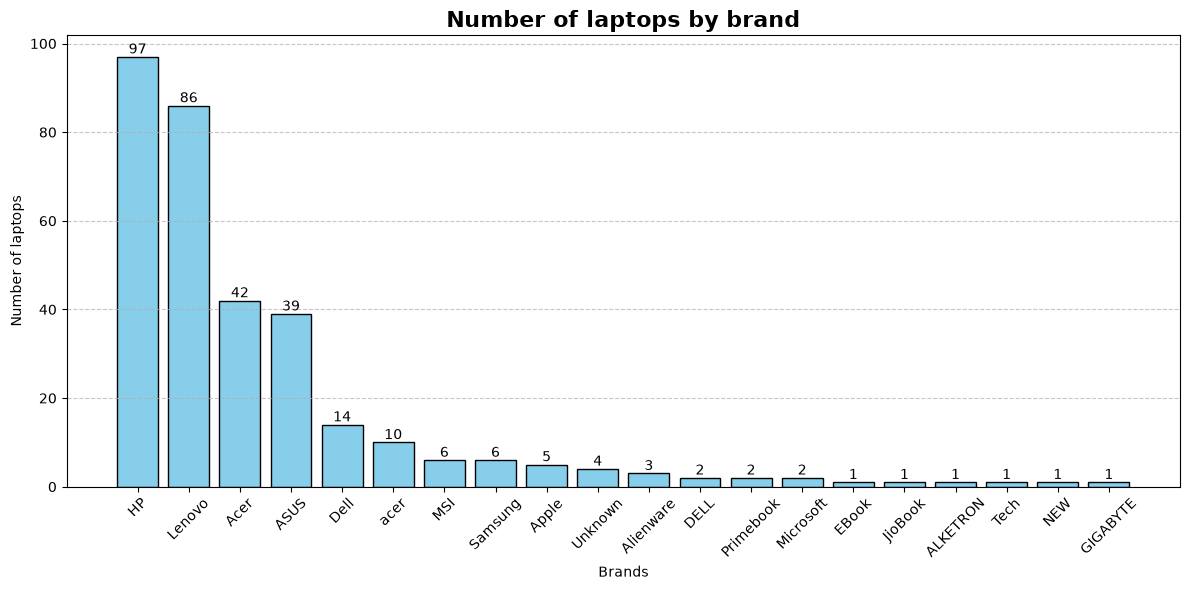

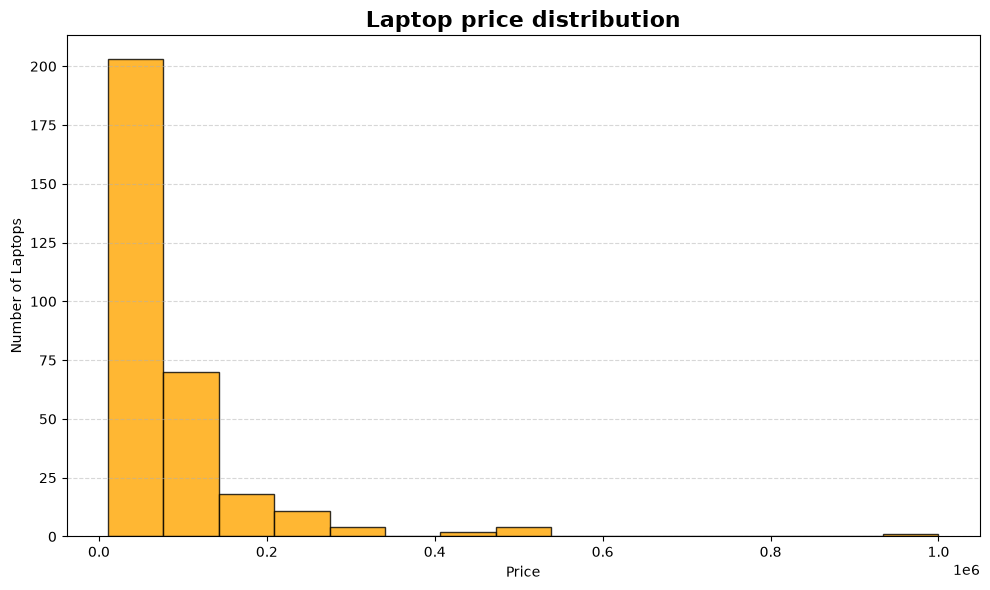

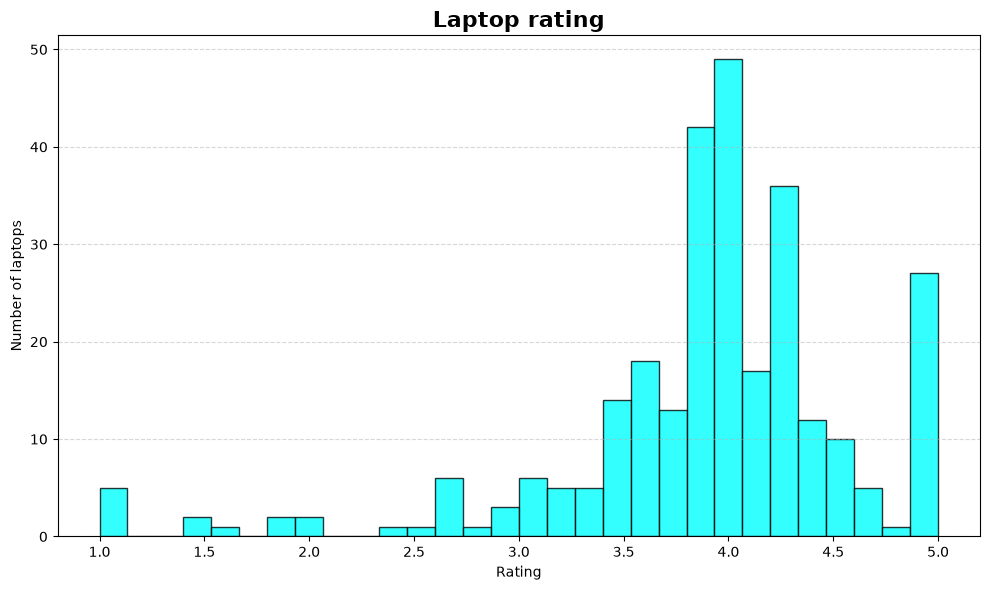

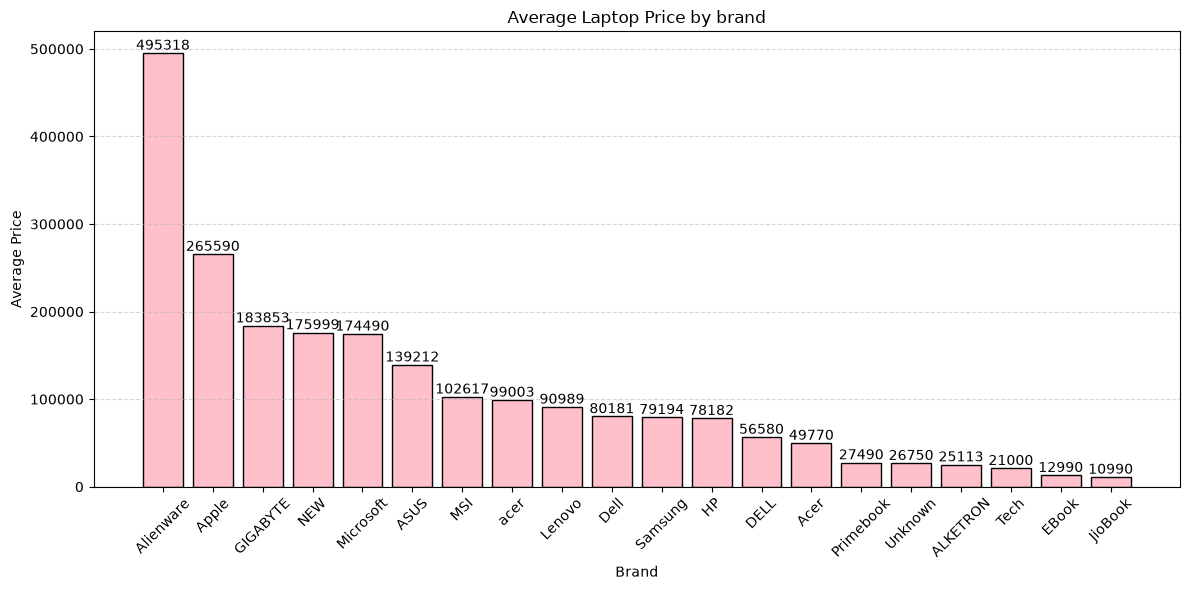

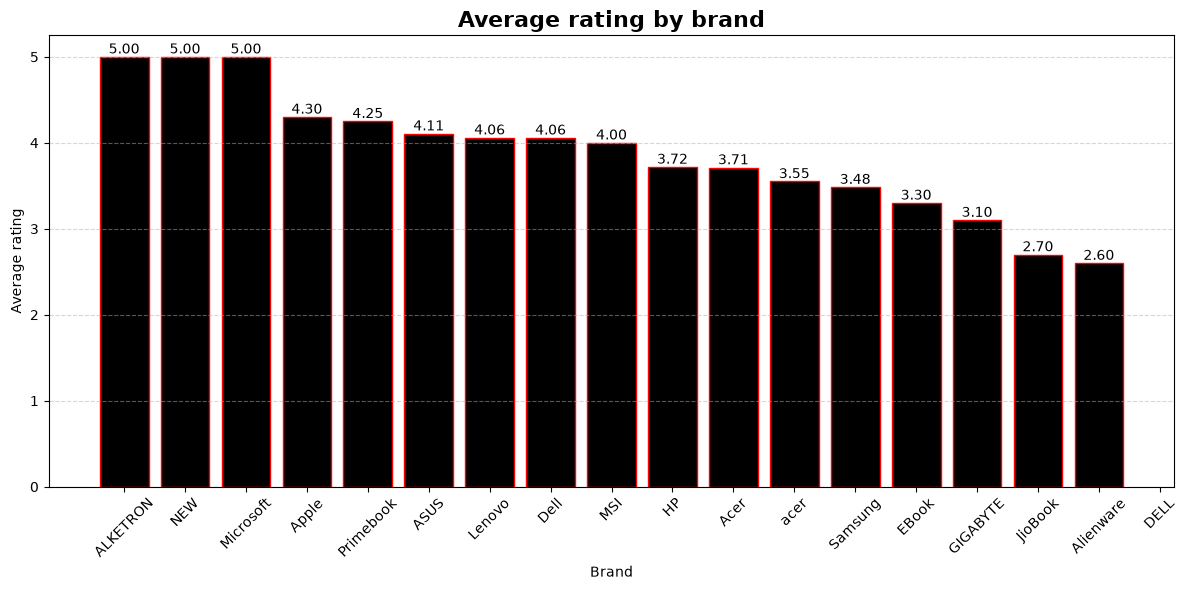

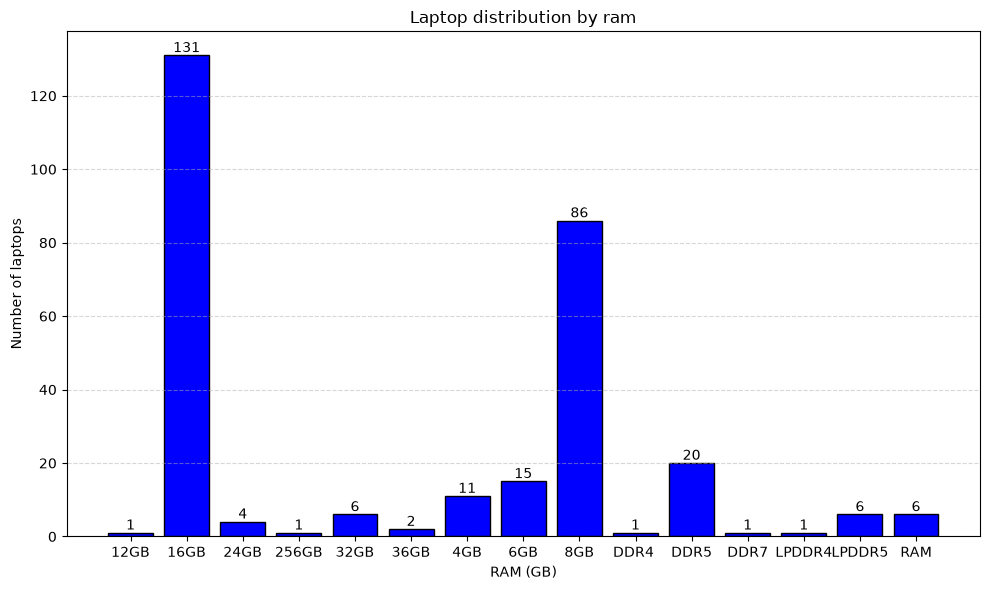

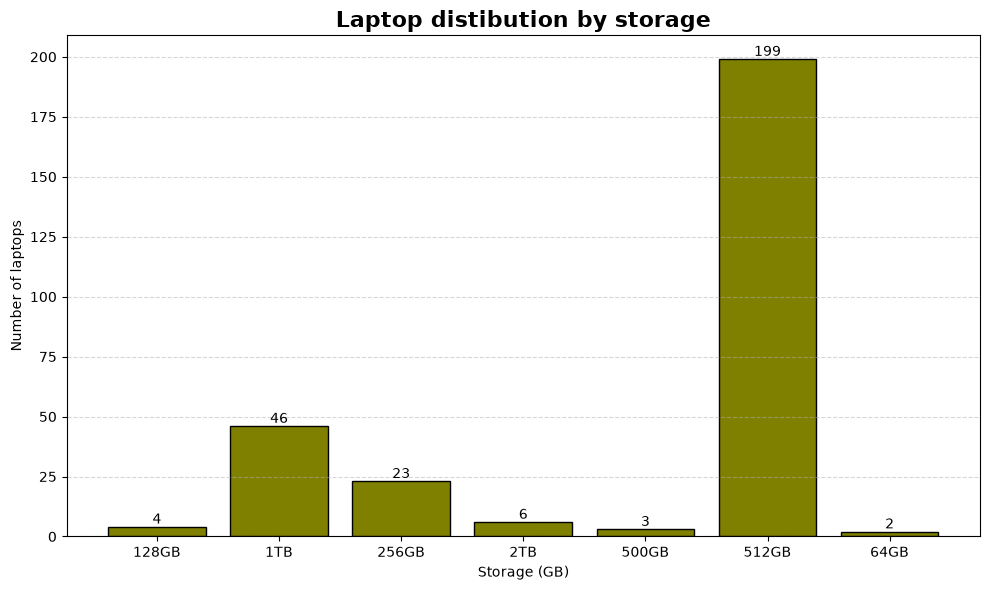

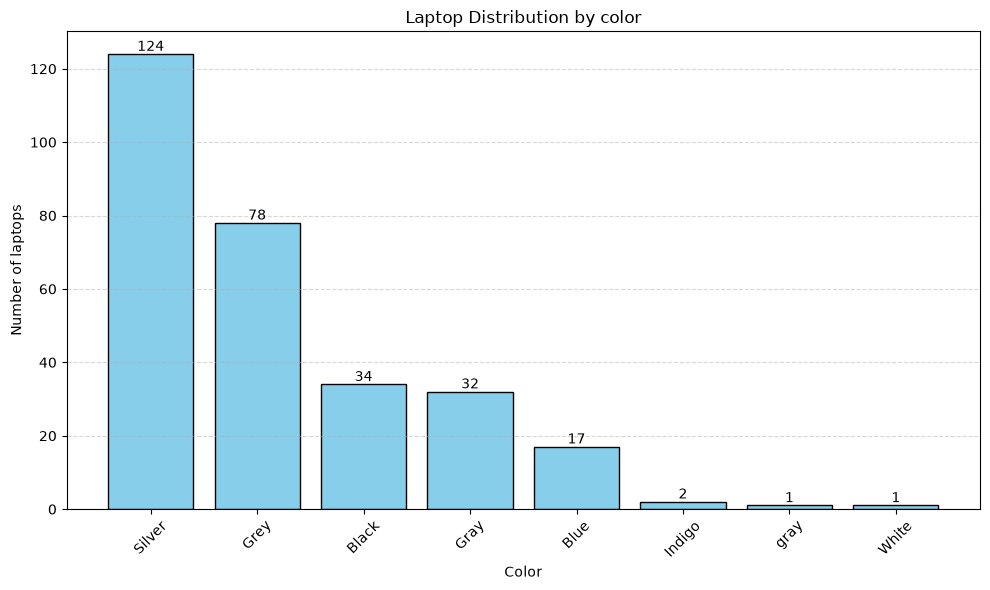

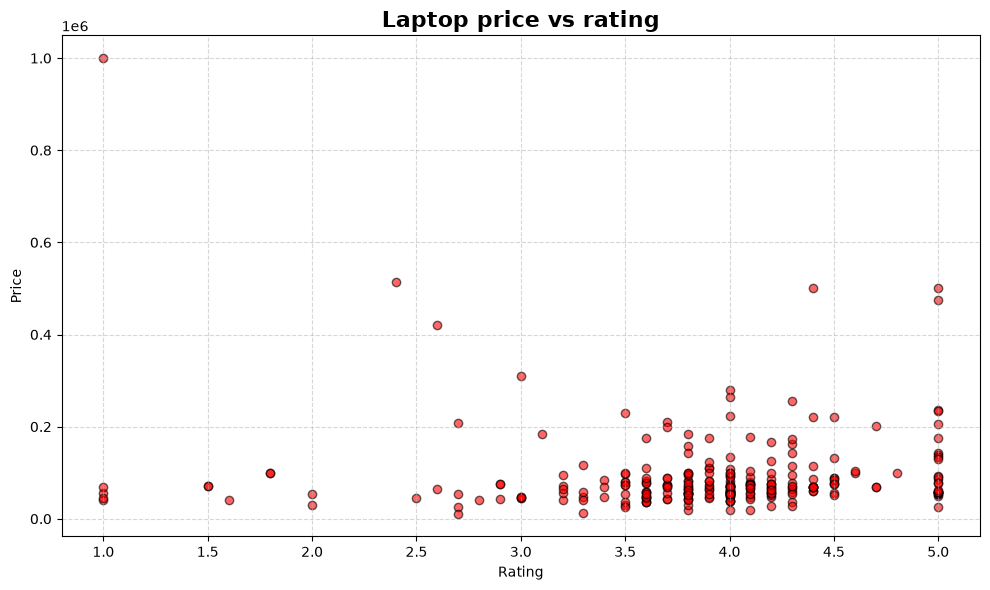

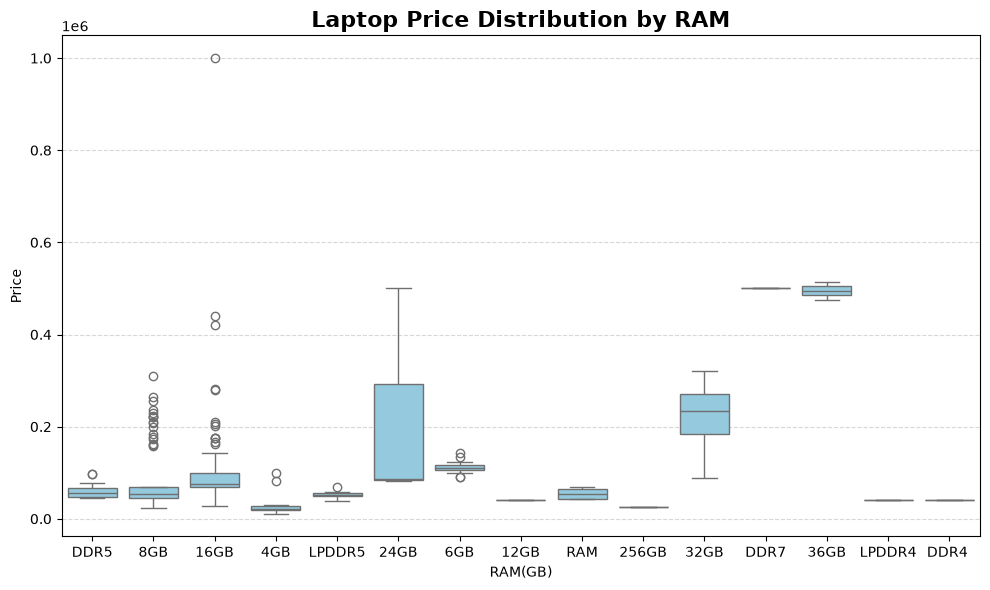

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
notebook_dir = Path.cwd()
csv_path = notebook_dir / "amazon_laptop_scraping_data.csv"
if not csv_path.exists():
    csv_path = notebook_dir.parent / "notebooks" / "amazon_laptop_scraping_data.csv"
df = pd.read_csv(csv_path)
df["price"] = pd.to_numeric(df["price"].astype(str).str.replace(",", "", regex=False), errors="coerce")
print("First five rows:")
display(df.head())
print("\nShape of the data:",df.shape)
print("Column names in the dataset:",df.columns)
print("\ndata types of each column:")
display(df.dtypes)
print("Missing valuyes:",df.isnull().sum())
#Number of laptops by brand
brands_data  = df["brand"].value_counts().sort_values(ascending=False)
plt.figure(figsize=(12,6))
bars = plt.bar(brands_data.index,brands_data.values, color='skyblue',edgecolor='black')
plt.title("Number of laptops by brand",fontsize=16,fontweight='bold')
plt.xlabel("Brands")
plt.ylabel("Number of laptops")
plt.xticks(rotation=45)
plt.grid(axis='y',linestyle="--",alpha=0.7)
for bar in bars:
    plt.text(bar.get_x()+bar.get_width()/2,bar.get_height(),f"{bar.get_height():.0f}",ha='center',va='bottom')
plt.tight_layout()
plt.show()
#Laptop Price Distribution
plt.figure(figsize=(10,6))
plt.hist(df["price"],bins=15,color='orange',edgecolor='black',alpha=0.8)
plt.title("Laptop price distribution",fontsize=16,fontweight='bold')
plt.xlabel("Price")
plt.ylabel("Number of Laptops")
plt.grid(True, axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()
#Laptop Rating
plt.figure(figsize=(10,6))
plt.hist(df["rating"],bins=30,color='cyan',edgecolor='black',alpha=0.8)
plt.title("Laptop rating",fontsize=16,fontweight='bold')
plt.xlabel("Rating")
plt.ylabel("Number of laptops")
plt.grid(axis='y',linestyle='--',alpha=0.5)
plt.tight_layout()
plt.show()
#Average Laptop Price by brand
brand_price = (df.groupby("brand")['price'].mean().sort_values(ascending=False))
plt.figure(figsize=(12,6))
bars = plt.bar(brand_price.index,brand_price.values,color="pink",edgecolor='black')
plt.title("Average Laptop Price by brand")
plt.xlabel("Brand")
plt.ylabel("Average Price")
plt.xticks(rotation=45)
plt.grid(axis='y',linestyle='--',alpha=0.5) 
for bar in bars:
    plt.text(bar.get_x() + bar.get_width() / 2,bar.get_height(),f"{bar.get_height():.0f}",ha="center",va="bottom") 
plt.tight_layout()
plt.show()
#Average rating by brand  
brand_rating = df.groupby("brand")["rating"].mean().sort_values(ascending=False)
plt.figure(figsize=(12,6))
bars = plt.bar(brand_rating.index,brand_rating.values,color='black',edgecolor='red')
plt.title("Average rating by brand",fontsize=16,fontweight='bold')
plt.xlabel("Brand")
plt.ylabel("Average rating")
plt.xticks(rotation=45)
plt.grid(axis='y',linestyle='--',alpha=0.5)
for bar in bars:
    plt.text(bar.get_x()+bar.get_width()/2,bar.get_height(),f"{bar.get_height():.2f}",ha="center",va="bottom")
plt.tight_layout()
plt.show()
#Laptop Distribution by ram
ram_data = df["RAM"].value_counts().sort_index()
plt.figure(figsize=(10,6))
bars = plt.bar(ram_data.index.astype(str),ram_data.values,color="blue",edgecolor="black")
plt.title("Laptop distribution by ram")
plt.xlabel("RAM (GB)")
plt.ylabel("Number of laptops")
plt.grid(axis="y",linestyle="--",alpha=0.5)
for bar in bars:
    plt.text(bar.get_x()+bar.get_width()/2,bar.get_height(),f"{bar.get_height():.0f}",ha="center",va="bottom")
plt.tight_layout()
plt.show()
#Laptop Distribution by storage
storage_data = df["Storage"].value_counts().sort_index()
plt.figure(figsize=(10,6))
bars = plt.bar(storage_data.index.astype(str),storage_data.values,color="olive",edgecolor="black")
plt.title("Laptop distibution by storage",fontsize=16,fontweight="bold")
plt.xlabel("Storage (GB)")
plt.ylabel("Number of laptops")
plt.grid(axis="y",linestyle="--",alpha=0.5)
for bar in bars:
    plt.text(bar.get_x()+bar.get_width()/2,bar.get_height(),f"{bar.get_height():.0f}",ha="center",va="bottom")
plt.tight_layout()
plt.show()
#Laptop Distribution by color
color_data = (df["Color"].value_counts().sort_values(ascending=False))
plt.figure(figsize=(10,6))
bars = plt.bar(color_data.index,color_data.values,color='skyblue',edgecolor='black')
plt.title("Laptop Distribution by color")
plt.xlabel("Color")
plt.ylabel("Number of laptops")
plt.xticks(rotation=45)
plt.grid(axis='y',linestyle="--",alpha=0.5)
for bar in bars:
    plt.text(bar.get_x()+bar.get_width()/2,bar.get_height(),f"{bar.get_height():.0f}",ha="center",va="bottom")
plt.tight_layout()
plt.show()
#Laptop Price vs rating
price_rating = df[["price","rating"]].dropna()
plt.figure(figsize=(10,6))
plt.scatter(price_rating["rating"],price_rating["price"],color="red",alpha=0.6,edgecolor="black")
plt.title("Laptop price vs rating",fontsize=16,fontweight="bold")
plt.xlabel("Rating")
plt.ylabel("Price")
plt.grid(True,linestyle="--",alpha=0.5)
plt.tight_layout()
plt.show()
#Price distribution by ram
ram_price = df[["RAM","price"]].dropna()
plt.figure(figsize=(10,6))
sns.boxplot(data=ram_price,x="RAM",y="price",color='skyblue')
plt.title("Laptop Price Distribution by RAM",fontsize=16,fontweight="bold")
plt.xlabel("RAM(GB)")
plt.ylabel("Price")
plt.grid(True,axis="y",linestyle="--",alpha=0.5)
plt.tight_layout()
plt.show()
